# Homework 9: Numerov and Verlet methods

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2025)  
**This homework assignment is due November 12, 2025, at 8 am.**   
(Submission via the shared `GitHub` repository.)

**Before you submit your homework, make sure that you click `Kernel > Restart & Run All`**.

## Numerov method for solving the one-dimensional Schrödinger equation

In this exercise, we explore another efficient method for solving Schrödinger equation. Numerov's method (also called Cowell's method) is a numerical method to solve ordinary differential equations of second order without a first-order term. 

The one-dimensional time-independent Schrödinger equation is
$$
-\frac{\hbar^2}{2m} \frac{d^2\psi}{dx^2} + V(x) \psi(x) = E \psi(x) \,,
$$
where $\psi(x)$ is the wavefunction, $V (x)$ is the potential energy, $m$ is the mass, and $\hbar$ is the reduced Planck’s constant. This is an eigenvalue problem since one can only find a solution that vanishes at $\pm \infty$ (the boundary conditions) for certain discrete values of $E$.

To find the energy eigenvalues, we need to be able to integrate the equation with respect
to $x$, for a given value of $E$, starting at $x = x_0$, i.e., with some specified values for $x = x_0$ and $x = x_1 = x_0 + h$, where $h$ is the step size. Using the notation $x_n = x_0 + nh$ and $\psi_n ≡ \psi(x_n)$, we need to solve for $\psi_2$, $\psi_3$, ... , given $\psi_0$ and $\psi_1$. 

Having solved the equation for a given value of $E$, we need to vary $E$ until we find a solution that satisfies the boundary conditions, which requires re-solving the equation for each value of $E$. We discussed this "shooting method" in class.

In the following, we focus on the problem of integrating the equation for a given value of $E$. One method
would be to use 4-th order Runge-Kutta (RK4), since it is is quite accurate. As discussed in the lecture, RK4 involves writing the Schrödinger equation, a second-order differential equation, as two first-order differential equations:

\begin{align*}
\frac{d\psi}{dx} &= \phi(x)\\
\frac{d\phi}{dx} &= −k^2(x)\psi(x) \,, \quad \mathrm{with} \quad 
k^2(x) = \frac{2m}{\hbar^2} (E − V (x)) \,.
\end{align*}

Recall that this a fourth-order method, i.e., the error is proportional to $h^4$.

Alternatively, one may consider the Schrödinger equation as a second order equation,
$$\boxed{
\frac{d^2\psi}{dx^2} + k^2(x) \psi(x) = 0 \,,
}$$
and take advantage of its particular structure (it is linear in $\psi$ and there is no term involving the first derivative.) A suitable algorithm for this type of problem is the **Numerov algorithm**, which is simpler than RK4 and one order higher in accuracy (i.e., at fifth order in $h$).

We now describe the Numerov method (see also Landau & Páez). A Taylor series for $\psi(x + h)$
gives
$$
\psi(x + h) = \psi(x) + h\psi^{(1)}(x) + \frac{h^2}{2} \psi^{(2)}(x) + \frac{h^3}{6} \psi^{(3)}(x) + \frac{h^4}{24} \psi^{(4)}(x) + \ldots \,. \qquad (5)
$$
Adding this to the series for $\psi(x − h)$ all the odd powers of $h$ vanish:
$$
\psi(x + h) + \psi(x − h) = 2\psi(x) + h^2\psi^{(2)}(x) + \frac{h^4}{12} \psi^{(4)}(x) + O(h^6) \,. \qquad (6)
$$
We can therefore write the second derivative which occurs in the Schrödinger equation, i.e., the boxed equation, as
$$
\psi^{(2)}(x) = \frac{\psi(x + h) + \psi(x − h) − 2\psi(x)}{h^2} − \frac{h^2}{12} \psi^{(4)}(x) + O(h^4) \,. \qquad (7)
$$
We would like to evaluate the term involving the fourth derivative. To do so, we act on the boxed equation with $1 + (h^2/12)d^2/dx^2$, giving
$$
\psi^{(2)}(x) + \frac{h^2}{12} \psi^{(4)}(x) + k^2(x)\psi(x) + \frac{h^2}{12} \frac{d^2}{dx^2}
\left[ k^2(x)\psi(x) \right] = 0 \,. \qquad (8)
$$
Substituting for $\psi^{(2)}(x) + \frac{h^2}{12} \psi^{(4)}(x)$ from Eq. (8) into Eq. (7) gives
$$
\psi(x + h) + \psi(x − h) − 2\psi(x) + h^2k^2(x)\psi(x) + \frac{h^4}{12} \frac{d^2}{dx^2}
[k^2(x)\psi(x)] + O(h^6) = 0 \,. \qquad (9)
$$

We evaluate $\frac{d^2}{dx^2} [k^2(x)\psi(x)]$ by using an elementary difference formula (this has an error $O(h^2)$ but is accurate enough because this term is already multiplied by $h^4$ in Eq. (9):
$$
\frac{d^2}{dx^2} [k^2(x)\psi(x)] \approx \frac{k^2(x + h)\psi(x + h) + k^2(x − h)\psi(x − h) − 2k^2(x)\psi(x)}{h^2} \, . \qquad (10)
$$
Substituting Eq. (10) into Eq. (9) and rearranging we get the Numerov algorithm for one time
step:
$$
\psi(x + h) = \frac{2 (1 − \frac{5}{12} h^2k^2(x)) \psi(x) − (1 + \frac{1}{12} h^2k^2(x − h)) \psi(x − h)}{1 + \frac{1}{12} h^2k^2(x + h)} + O(h^6) \,. \qquad (11)
$$
Setting $x = x_n ≡ x_0 + nh$, and defining $k_n ≡ k(x_n)$, this can be written as
$$\boxed{
\psi_{n+1} = \frac{2 (1 − \frac{5}{12} h^2k^2_n) \psi_n − (1 + \frac{1}{12} h^2k^2_{n−1}) \psi_{n−1}}{1 +\frac{1}{12} h^2k^2_{n+1}} \,, \qquad (12)
}$$
with an error of order $h^6$. The Numerov method, Eq. (12), can be used to determine $\psi_n$ for
$n = 2, 3, 4, \ldots$ , given two initial values, $\psi_0$ and $\psi_1$.

The error in one time step is $O(h^6)$. However, the number of steps needed to integrate over a fixed range of $x$ from $x_0$ to $x_0 + \Delta x$ is $\Delta x/h$. The
errors in each step add up and so the total error in the Numerov method is $O(h^5)$, i.e. it is a
fifth order method, one higher than RK4. However, there can be significant issues with [roundoff errors](https://www.sciencedirect.com/science/article/pii/0021999178900633?ref=pdf_download&fr=RR-2&rr=82d6f8fd7e24e14f) in using Eq. (12).

a) Use the **shooting method** combined with the **Numerov algorithm** to solve the Schrödinger equation for trapped electrons:

$$ \boxed{
−\frac{d^2}{d\rho^2} \psi(\rho) + \rho^2 \psi(\rho) + \frac{\gamma}{\rho} \psi(\rho) 
= \lambda \psi(\rho) \,,}
$$

with the boundary condition $\psi(\rho=0) = \psi(\rho=\rho_\mathrm{max}) =0 $ for some sufficiently large $\rho_\mathrm{max}$. Normalize the wavefunctions, i.e., such that

$$
1 = \int_0^\infty d\rho \, \rho^2 |\psi(\rho)|^2
$$

Consider the cases $\gamma = 0, 0.5, 1, 2$, and $4$ for the **ground state only**, that is the lowest-lying state.

**Hint:** For $\gamma = 0$, we know the (dimensionless) energies $\lambda$ analytically: $\lambda_0 =3$, $\lambda_1 =7$, $\lambda_2 =11$, etc. 

In [1]:
#Question 1.) Part A.

import numpy as np 
from scipy.optimize import brentq 
import matplotlib.pyplot as plt 

#intialized variables 
rho_max = 5.0 #large maxima cutoff 
h = 0.01 #stepsize of problem 
N = int(rho_max/h) #number of steps
rho = np.linspace(0.0, rho_max, N + 1) #gridpoints for rho 


#function for the potential energy 
def V_pot(r, alpha): 
    '''
    Function essentially defines potential associated with the Shrodinger equation. 

    Parameters: 
    ----------
    r, alpha:  float and/or numpy array 
    r's are the radiuses of system. alphas are the dimensionless constants associated. 

    Return: 
    ------
    numpy array 
    essentially returns each elemental potential term. 

    '''
    if r == 0.0: 
        return 0.0 
    else: 
        return (r**2 + (alpha/r))


#function that performs numerov algorithm 
def numerov(alpha, lamb):
    ''' Functions that runs the numerov program. 

    Parameters: 
    -----------
    alpha, lamb: float or list/array type 
    Alpha's are the dimensionless paramters. lambdas are the energy eigenvalues. 

    Return: 
    ------
    array/list type 
    Outputting of the wavefunction elements for trapped electrons(s) system. 

    '''
    
    psi = np.zeros(N + 1)
    psi[0] = 1e-12
    psi[1] = h 
    k = [] 
    for i in range(len(rho)): 
        r = rho[i]
        k.append(lamb - V_pot(r, alpha)) 
    for n in range(1, N): 
        num = (2.0 * psi[n] * (1.0 - (5.0/12.0) * h**2 * k[n])
               - psi[n-1] * (1.0 + (1.0/12.0) * h**2 * k[n-1]))
        dem = (1.0 + (1.0/12.0)*h**2 * k[n+1]) 
        psi[n+1] = num/dem 
    return psi 

#function that'll define the shooting for lambda
def F(alpha, lamb):
    '''
    Used for shooting method "root finding" function just define last element that 
    should correspond to zro subjected to boundary condition.

    Paramters: 
    ----------
    alpha, lamb: float or list/array type 
    Alpha's are the dimensionless paramters. lambdas are the energy eigenvalues.

    Return: 
    ------
    last element of list 
    This function just defines last element of list subjected to root finding problem. 

    '''
    
    return numerov(alpha, lamb)[-1]

def ground_state(alpha): 
    '''
    This function defines the ground state wavefunction that's normalized. 
    also gets energy eigenvlaues via specialized bisection.

    Parameter: 
    ----------
    alpha: float or list/array type 
    Alpha's are the dimensionless paramters. 

    Return: 
    -------
    float and list 
    Outputs the energy eigenvalues and ground state elements. 

    '''
    
    lam = brentq(lambda lam: F(alpha, lam), 2.0, 6.7)
    psi_final = numerov(alpha, lam) 
    norm = np.sqrt(np.trapezoid((rho**2) * (psi_final**2), rho))
    psi_final /= norm         
    return lam, psi_final 



    
#display of answers for ground state
alpha = [0.0, 0.5, 1.0, 2.0, 4.0]
psi_vec = [] 
for a in alpha:
    f_lam, f_psi = ground_state(a) 
    psi_vec.append(f_psi)  
    print(f" lambda = {f_lam:.5f}")


 lambda = 3.00000
 lambda = 3.54567
 lambda = 4.05787
 lambda = 4.99999
 lambda = 6.64567


b) Repeat the exercise in a) using `scipy.integrate.solve_ivp()` applied to a pair of first-order differential equations instead of the Numerov algorithm. Plot the wave functions obtained in a) and b) and their residuals (i.e., difference). Your figure should have 2 panels, legends, and axis labels.

 lambda_rk = 2.99962
 lambda_num = 3.00000
 lambda_rk = 3.54502
 lambda_num = 3.54567
 lambda_rk = 4.05735
 lambda_num = 4.05787
 lambda_rk = 4.99966
 lambda_num = 4.99999
 lambda_rk = 6.64534
 lambda_num = 6.64567


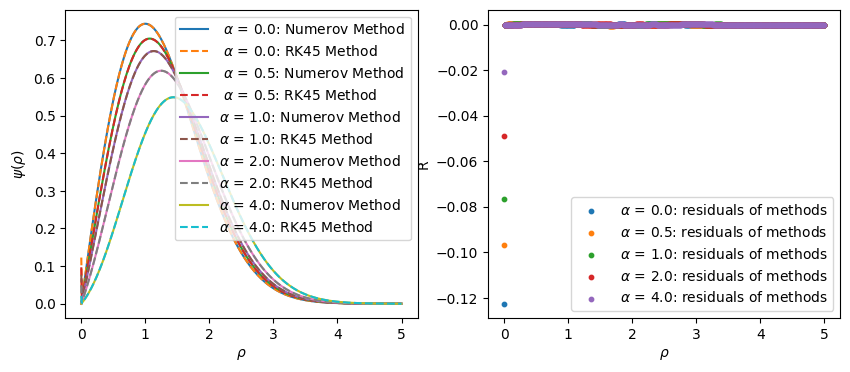

In [2]:
#Question 1.) Part B.

import numpy as np
from scipy.optimize import brentq
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# 1 row, 2 columns of subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))


def Coupled_ODEs(r, y, alpha, lam): 
    ''' Decomposition of 2nd order ODE into first order terms. 

    Parameter: 
    ---------
    r: float 
    position coordinates. 
    y: list or numpy array 
    Splitting of each 1st order term from 2nd order. also used for initial conditions. 
    alpha: float or list/array type
    Alpha's are the dimensionless paramters. 
    lamb: float or list/array type
    lambdas are the energy eigenvalues.

    Return: 
    -------
    List
    Each 1st order system element. 

    '''
    psi, dpsi = y
    return [dpsi, (-lam + V_pot(r, alpha)) * psi]

def psi_ivp(alpha, lam):
    '''
    Function that uses the rk45 python solver for 1st order elements. also evaluated at sam rho range. 


    Parameter: 
    ---------
    alpha, lamb: float or list/array type 
    Alpha's are the dimensionless paramters. lambdas are the energy eigenvalues.

    Return: 
    -------
    list or numpy array
    Wavefunction (psi) of system using rk45 solver. 

    '''
    
    r0 = h
    y0 = [r0, 1.0]
    sol = solve_ivp(
        Coupled_ODEs,
        (r0, rho_max),
        y0,
        args=(alpha, lam),
        t_eval=rho[1:])
    psi = np.zeros_like(rho)
    psi[0] = 0.1
    psi[1:] = sol.y[0]
    return psi

def F_ivp(alpha, lam):
    '''
    Used for shooting method "root finding" function just define last element that 
    should correspond to zro subjected to boundary condition. rk45 approach.

    Paramters: 
    ----------
    alpha, lamb: float or list/array type 
    Alpha's are the dimensionless paramters. lambdas are the energy eigenvalues.

    Return: 
    ------
    last element of list 
    This function just defines last element of list subjected to root finding problem. rk45 approach.

    '''
    psi = psi_ivp(alpha, lam)
    return psi[-1]


def ground_state_Ivp(alpha): 
    '''
    This function defines the ground state wavefunction that's normalized. 
    also gets energy eigenvlaues via specialized bisection. for rk45 approach.

    Parameter: 
    ----------
    alpha: float or list/array type 
    Alpha's are the dimensionless paramters. 

    Return: 
    -------
    float and list 
    Outputs the energy eigenvalues and ground state elements. for rk45 approach. 

    '''
    lam = brentq(lambda lam: F_ivp(alpha, lam), 2.0 , 6.7)
    psi_final_ivp = psi_ivp(alpha, lam) 
    norm = np.sqrt(np.trapezoid((rho**2) * (psi_final_ivp**2), rho))
    psi_final_ivp /= norm 
    return lam, psi_final_ivp 

#display of answers for ground state
alpha = [0.0, 0.5, 1.0, 2.0, 4.0]
psi_vec_ivp = [] 
psi_vec = [] 
Residuals = [] 
for a in alpha:
    f_lam1, f_psi1 = ground_state_Ivp(a) 
    psi_vec_ivp.append(f_psi1)  
    print(f" lambda_rk = {f_lam1:.5f}")
    f_lam, f_psi = ground_state(a) 
    psi_vec.append(f_psi)  
    print(f" lambda_num = {f_lam:.5f}")

for i in range(len(psi_vec)): 
    Residuals.append(psi_vec[i] - psi_vec_ivp[i])


#plotting functions for both approaches 
axes[0].plot(rho, psi_vec[0], label = r" $\alpha$ = 0.0: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[0], "--", label = r" $\alpha$ = 0.0: RK45 Method") 
axes[0].plot(rho, psi_vec[1], label = r" $\alpha$ = 0.5: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[1], "--", label = r" $\alpha$ = 0.5: RK45 Method") 
axes[0].plot(rho, psi_vec[2], label = r"$\alpha$ = 1.0: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[2], "--", label = r"$\alpha$ = 1.0: RK45 Method") 
axes[0].plot(rho, psi_vec[3], label =  r"$\alpha$ = 2.0: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[3], "--", label = r"$\alpha$ = 2.0: RK45 Method") 
axes[0].plot(rho, psi_vec[4], label = r"$\alpha$ = 4.0: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[4], "--", label = r"$\alpha$ = 4.0: RK45 Method") 
axes[0].set_xlabel(r"$\rho$")
axes[0].set_ylabel(r"$\psi(\rho)$")
axes[0].legend(loc="best")


axes[1].scatter(rho, Residuals[0], s=10, marker='o', label = r" $\alpha$ = 0.0: residuals of methods")   
axes[1].scatter(rho, Residuals[1], s=10, marker='o', label = r" $\alpha$ = 0.5: residuals of methods")  
axes[1].scatter(rho, Residuals[2], s=10, marker='o', label = r" $\alpha$ = 1.0: residuals of methods")  
axes[1].scatter(rho, Residuals[3], s=10, marker='o', label = r" $\alpha$ = 2.0: residuals of methods")  
axes[1].scatter(rho, Residuals[4], s=10, marker='o', label = r" $\alpha$ = 4.0: residuals of methods")  
axes[1].set_xlabel(r"$\rho$")
axes[1].set_ylabel("R")
axes[1].legend(loc="best")


    







c) Repeat the exercise in b) for the first excited state. 

 lambda = 7.00000
 lambda = 7.46245
 lambda = 7.90966
 lambda = 8.76046
 lambda = 6.64567
 lambda_rk = 6.99864
 lambda_num = 7.00000
 lambda_rk = 7.46096
 lambda_num = 7.46245
 lambda_rk = 7.90814
 lambda_num = 7.90966
 lambda_rk = 8.75901
 lambda_num = 8.76046
 lambda_rk = 6.64534
 lambda_num = 6.64567


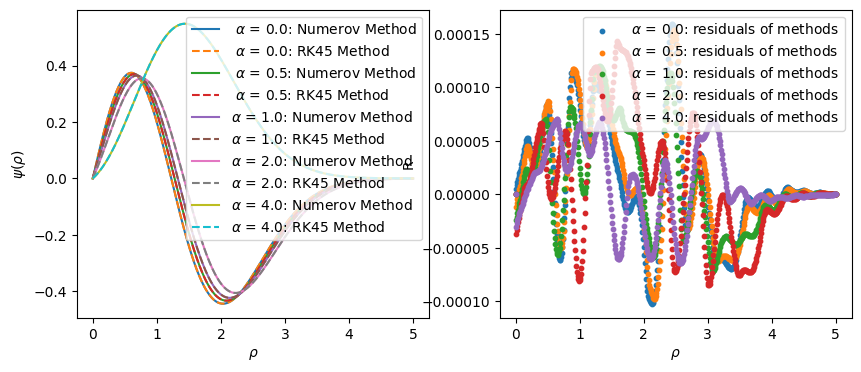

In [3]:
#Question 1. Part C.) 


import numpy as np 
from scipy.integrate import solve_ivp
from scipy.optimize import brentq 
import matplotlib.pyplot as plt 

#intialized variables 
rho_max = 5.0 #large maxima cutoff 
h = 0.01 #stepsize of problem 
N = int(rho_max/h) #number of steps
rho = np.linspace(0.0, rho_max, N + 1) #gridpoints for rho 


#function for the potential energy 
def V_pot1(r, alpha): 
    '''
    Function essentially defines potential associated with the Shrodinger equation. 

    Parameters: 
    ----------
    r, alpha:  float and/or numpy array 
    r's are the radiuses of system. alphas are the dimensionless constants associated. 

    Return: 
    ------
    numpy array 
    essentially returns each elemental potential term. 

    '''
    if r == 0.0: 
        return 0.0 
    else: 
        return (r**2 + (alpha/r))


#function that performs numerov algorithm 
def numerov1(alpha, lamb): 
    ''' Functions that runs the numerov program. 

    Parameters: 
    -----------
    alpha, lamb: float or list/array type 
    Alpha's are the dimensionless paramters. lambdas are the energy eigenvalues. 

    Return: 
    ------
    array/list type 
    Outputting of the wavefunction elements for trapped electrons(s) system. For 1st exc state system. 

    '''
    psi = np.zeros(N + 1)
    psi[0] = 1e-12 
    psi[1] = h 
    k = [] 
    for i in range(len(rho)): 
        r = rho[i]
        k.append(lamb - V_pot(r, alpha)) 
    for n in range(1, N): 
        num = (2.0 * psi[n] * (1.0 - (5.0/12.0) * h**2 * k[n])
               - psi[n-1] * (1.0 + (1.0/12.0) * h**2 * k[n-1]))
        dem = (1.0 + (1.0/12.0)*h**2 * k[n+1]) 
        psi[n+1] = num/dem 
    return psi 

#function that'll define the shooting for lambda
def F1(alpha, lamb): 
    '''
    Used for shooting method "root finding" function just define last element that 
    should correspond to zro subjected to boundary condition.

    Paramters: 
    ----------
    alpha, lamb: float or list/array type 
    Alpha's are the dimensionless paramters. lambdas are the energy eigenvalues.

    Return: 
    ------
    last element of list 
    This function just defines last element of list subjected to root finding problem. 

    '''
    return numerov(alpha, lamb)[-1]

def Fst_exc_state(alpha): 
    '''
    This function defines the 1st exc state wavefunction that's normalized. 
    also gets energy eigenvlaues via specialized bisection.

    Parameter: 
    ----------
    alpha: float or list/array type 
    Alpha's are the dimensionless paramters. 

    Return: 
    -------
    float and list 
    Outputs the energy eigenvalues and ground state elements. 

    '''
    lam = brentq(lambda lam: F1(alpha, lam), 5.0, 10.0)
    psi_final1 = numerov1(alpha, lam) 
    norm1 = np.sqrt(np.trapezoid((rho**2) * (psi_final1**2), rho))
    psi_final1 /= norm1 
    return lam, psi_final1 



    
#display of answers for ground state
alpha = [0.0, 0.5, 1.0, 2.0, 4.0]
psi_vec = [] 
for a in alpha:
    f_lam, f_psi = Fst_exc_state(a) 
    psi_vec.append(f_psi)  
    print(f" lambda = {f_lam:.5f}")




# 1 row, 2 columns of subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4))


def Coupled_ODEs(r, y, alpha, lam): 
    ''' Decomposition of 2nd order ODE into first order terms. 

    Parameter: 
    ---------
    r: float 
    position coordinates. 
    y: list or numpy array 
    Splitting of each 1st order term from 2nd order. also used for initial conditions. 
    alpha: float or list/array type
    Alpha's are the dimensionless paramters. 
    lamb: float or list/array type
    lambdas are the energy eigenvalues.

    Return: 
    -------
    List
    Each 1st order system element. 

    '''
    psi, dpsi = y
    return [dpsi, (-lam + V_pot(r, alpha)) * psi]

def psi_ivp(alpha, lam):
    '''
    Function that uses the rk45 python solver for 1st order elements. also evaluated at sam rho range. 


    Parameter: 
    ---------
    alpha, lamb: float or list/array type 
    Alpha's are the dimensionless paramters. lambdas are the energy eigenvalues.

    Return: 
    -------
    list or numpy array
    Wavefunction (psi) of system using rk45 solver. 

    '''
    r0 = h
    y0 = [r0, 1.0]
    sol = solve_ivp(
        Coupled_ODEs,
        (r0, rho_max),
        y0,
        args=(alpha, lam),
        t_eval=rho[1:])
    psi = np.zeros_like(rho)
    psi[0] = 0.0
    psi[1:] = sol.y[0]
    return psi

def F_ivp(alpha, lam):
    '''
    Used for shooting method "root finding" function just define last element that 
    should correspond to zro subjected to boundary condition. rk45 approach.

    Paramters: 
    ----------
    alpha, lamb: float or list/array type 
    Alpha's are the dimensionless paramters. lambdas are the energy eigenvalues.

    Return: 
    ------
    last element of list 
    This function just defines last element of list subjected to root finding problem. rk45 approach.

    '''
    psi = psi_ivp(alpha, lam)
    return psi[-1]


def F_state_Ivp(alpha):
    '''
    This function defines the 1st exc state wavefunction that's normalized. 
    also gets energy eigenvlaues via specialized bisection. for rk45 approach.

    Parameter: 
    ----------
    alpha: float or list/array type 
    Alpha's are the dimensionless paramters. 

    Return: 
    -------
    float and list 
    Outputs the energy eigenvalues and ground state elements. for rk45 approach. 
    '''
    lam = brentq(lambda lam: F_ivp(alpha, lam), 5.0, 10.0)
    psi_final_ivp = psi_ivp(alpha, lam) 
    norm = np.sqrt(np.trapezoid((rho**2) * (psi_final_ivp**2), rho))
    psi_final_ivp /= norm 
    return lam, psi_final_ivp 

#display of answers for ground state
alpha = [0.0, 0.5, 1.0, 2.0, 4.0]
psi_vec_ivp = [] 
psi_vec = [] 
Residuals = [] 
for a in alpha:
    f_lam1, f_psi1 = F_state_Ivp(a) 
    psi_vec_ivp.append(f_psi1)  
    print(f" lambda_rk = {f_lam1:.5f}")
    f_lam, f_psi = Fst_exc_state(a) 
    psi_vec.append(f_psi)  
    print(f" lambda_num = {f_lam:.5f}")

for i in range(len(psi_vec)): 
    Residuals.append(psi_vec[i] - psi_vec_ivp[i])


#plotting functions for both approaches 
axes[0].plot(rho, psi_vec[0], label = r" $\alpha$ = 0.0: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[0], "--", label = r" $\alpha$ = 0.0: RK45 Method") 
axes[0].plot(rho, psi_vec[1], label = r" $\alpha$ = 0.5: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[1], "--", label = r" $\alpha$ = 0.5: RK45 Method") 
axes[0].plot(rho, psi_vec[2], label = r"$\alpha$ = 1.0: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[2], "--", label = r"$\alpha$ = 1.0: RK45 Method") 
axes[0].plot(rho, psi_vec[3], label =  r"$\alpha$ = 2.0: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[3], "--", label = r"$\alpha$ = 2.0: RK45 Method") 
axes[0].plot(rho, psi_vec[4], label = r"$\alpha$ = 4.0: Numerov Method")    
axes[0].plot(rho, psi_vec_ivp[4], "--", label = r"$\alpha$ = 4.0: RK45 Method") 
axes[0].set_xlabel(r"$\rho$")
axes[0].set_ylabel(r"$\psi(\rho)$")
axes[0].legend(loc="best")


axes[1].scatter(rho, Residuals[0], s=10, marker='o', label = r" $\alpha$ = 0.0: residuals of methods")   
axes[1].scatter(rho, Residuals[1], s=10, marker='o', label = r" $\alpha$ = 0.5: residuals of methods")  
axes[1].scatter(rho, Residuals[2], s=10, marker='o', label = r" $\alpha$ = 1.0: residuals of methods")  
axes[1].scatter(rho, Residuals[3], s=10, marker='o', label = r" $\alpha$ = 2.0: residuals of methods")  
axes[1].scatter(rho, Residuals[4], s=10, marker='o', label = r" $\alpha$ = 4.0: residuals of methods")  
axes[1].set_xlabel(r"$\rho$")
axes[1].set_ylabel("R")
axes[1].legend(loc="best")


    




    



## Orbit of the Earth 

Use the *Verlet method* to calculate the orbit of the Earth around the Sun. The equations of motion for the position $\vec{r} = (x,y)$ of the planet in its orbital plane are 

$$
{d^2\vec{r}\over dt^2} = -GM {\vec{r}\over r^3}\,,
$$

where $G=6.6738\times10^{-11}\,\mathrm{m^3\,kg^{-1}\,s^{-2}}$ is Newton's gravitational constant and $M=1.9891\times10^{30}$ kg is the mass of the Sun.

The orbit of the Earth is not perfectly circular; the planets are sometimes closer to and sometimes further from the Sun. When it is at its closest point, or *perihelion*, it is moving precisely tangentially (i.e., perpendicular to the line between itself and the Sun) and it has distance $1.4710 \cdot 10^{11}m$ from the Sun and linear velocity $3.0287\cdot 10^4 m/s$.

a) Write a `Python` program to calculate the orbit of the Earth using the **Verlet method**, with a time-step of $h=1$ hour. Plot the orbit and show several complete revolutions about the Sun. The orbit should be very slight but visibly non-circular.
  
b) Earth's gravitational potential energy is $-GMm/r$, where $m=5.9722\cdot 10^{24}kg$ is the mass of the planet, and its kinetic energy is ${1 \over 2} mv^2$ as usual. Modify your program to calculate both of these quantities at each step, along with their sum (which is the total energy), and make a plot showing all three as a function of time on the same axes. You should find that the potential and kinetic energies vary visibly during an orbit, but the total energy remains constant.

c) Now plot the total energy alone without the others, and you should be able to see a slight variation throughout an orbit. Because you are using the Verlet method, however, which conserves energy in the long term, the energy should always return to its starting value at the end of each complete orbit.

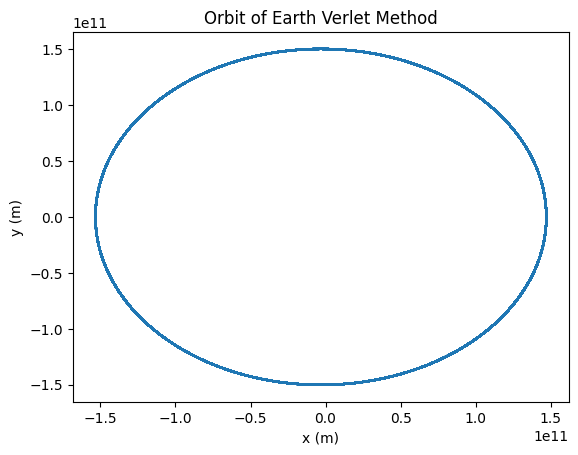

In [4]:
#Question 2.) Part a.) 

import numpy as np 
import math
import matplotlib.pyplot as plt 

#Constants Used 
G = 6.6738e-11 #unit: m^3*kg^-1*s^-2
M = 1.981e30 #unit: kg
h = 3600 #make certain that stepsizes 1 hr converted to sec steps
N = 1*365*24*3600 #number of steps accesible for seconds

#Intial conditions 
x_i = 1.4710e11 #unit: m 
y_i = 0.0 #unit: m 
v_xi = 0.0 #unit: m/s
v_yi = 3.0287e4 #unit: m/s


#Function for universal gravitation 
def F(x, y): 
    ''' This function calculates components for the force term. 

    Paramater: 
    ---------
    x: float or numpy array 
    x-comp of position
    y: float or numpy array 
    y-comp of position

    Return: 
    -------
    Fx, Fy: float or numpy array 
    Both components of Force terms. 
    '''

    r = math.sqrt(x**2 + y**2) 
    Fx = (-G * M * x)/(r**3) 
    Fy = (-G * M * y)/(r**3) 
    return Fx, Fy 



#initialize vectors 
x_pos = []
y_pos = [] 
V = [] 


#Inital acceleration 
a_xi, a_yi = F(x_i, y_i) 

#verlet process 
for i in range(N): 
    #list append 
    x_pos.append(x_i)
    y_pos.append(y_i) 
    #start verlet process 
    x_f = x_i + v_xi*h + 0.5*a_xi*h**2 
    y_f = y_i + v_yi*h + 0.5*a_yi*h**2 
    a_xf, a_yf = F(x_f, y_f) 
    v_xf = v_xi + 0.5*(a_xi + a_xf)*h 
    v_yf = v_yi + 0.5*(a_yi + a_yf)*h 
    x_i, y_i = x_f, y_f 
    v_xi, v_yi = v_xf, v_yf 
    a_xi, a_yi = a_xf, a_yf 


plt.plot(x_pos, y_pos)  
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.title('Orbit of Earth Verlet Method')
plt.show()

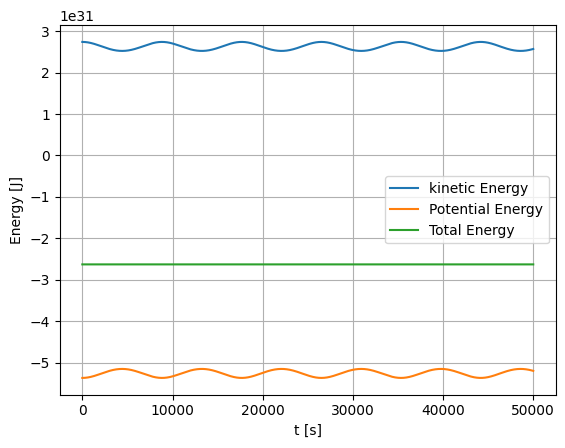

In [5]:
#Question 2.) Part b.) 

import numpy as np 
import math
import matplotlib.pyplot as plt 

#Constants Used 
G = 6.6738e-11 #unit: m^3*kg^-1*s^-2
M = 1.981e30 #unit: kg
h = 3600                     
N = 1*365*24*3600  
m = 5.9722e22

#Intial conditions 
x_i = 1.4710e11 #unit: m 
y_i = 0.0 #unit: m
r_i = math.sqrt(x_i**2 + y_i**2) 
v_xi = 0.0 #unit: m/s
v_yi = 3.0287e4 #unit: m/s
V_i = (-G * M * m)/(r_i)


#Function for universal gravitation 
def F(x, y): 
    ''' This function calculates components for the force term. 

    Paramater: 
    ---------
    x: float or numpy array 
    x-comp of position
    y: float or numpy array 
    y-comp of position

    Return: 
    -------
    Fx, Fy: float or numpy array 
    Both components of Force terms. 

    '''
    
    r = math.sqrt(x**2 + y**2) 
    Fx = (-G * M * x)/(r**3) 
    Fy = (-G * M * y)/(r**3) 
    return Fx, Fy 


#initialize vectors 
x_pos = []
y_pos = [] 
V = [] 
T = [] 
E = [] 


#Inital acceleration 
a_xi, a_yi = F(x_i, y_i) 


#verlet process 
for i in range(50000): 
    #list append 
    x_pos.append(x_i)
    y_pos.append(y_i) 
    #start verlet process 
    x_f = x_i + v_xi*h + 0.5*a_xi*h**2 
    y_f = y_i + v_yi*h + 0.5*a_yi*h**2 
    a_xf, a_yf = F(x_f, y_f) 
    v_xf = v_xi + 0.5*(a_xi + a_xf)*h 
    v_yf = v_yi + 0.5*(a_yi + a_yf)*h 
    #update
    x_i, y_i = x_f, y_f 
    v_xi, v_yi = v_xf, v_yf 
    a_xi, a_yi = a_xf, a_yf 
    #conservation setups
    V_f = (-G * M * m)/(math.sqrt(x_f**2 + y_f**2))
    T_f = 0.5*m*(v_xf**2 + v_yf**2)
    E_f = T_f + V_f 
    V.append(V_f) 
    T.append(T_f) 
    E.append(E_f)


t = np.arange(0, 50000)

#plotting sequences
plt.plot(t, T, label = "kinetic Energy") 
plt.plot(t, V, label = "Potential Energy")
plt.plot(t, E, label = "Total Energy")
plt.xlabel('t [s]')
plt.ylabel('Energy [J]')
plt.legend(loc="best")
plt.grid(True)
plt.show()

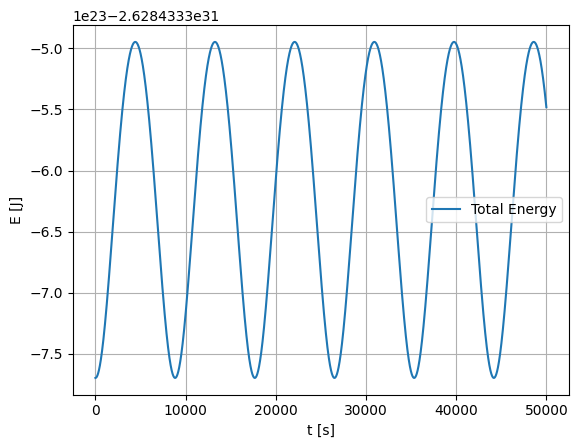

In [6]:
#Question 2.) Part c.) 

import numpy as np 
import math
import matplotlib.pyplot as plt


#plotting sequences
plt.plot(t, E, label = "Total Energy")
plt.xlabel('t [s]')
plt.ylabel('E [J]')
plt.legend(loc="best")
plt.grid(True)
plt.show()

